# Tugas Kelompok - Pertemuan 9
## Perangkat Keras Embedded & Hardware Abstraction

**Kelompok 10:**
1. Afelia Nasyifa (2411513010)
2. Muhammad Zulvi Prawira (2411512020)
3. Raffael Syahadat Fahlevi (2411513002)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:.4f}')

## 1. Mengganti skenario pemilihan hardware menjadi gateway Edge-AI

Pada Hands-On 1, fokus awalnya sensor node bertenaga baterai, jadi efisiensi daya diberi bobot terbesar. Sekarang saya ganti kasusnya menjadi gateway Edge-AI untuk mengolah citra kamera secara lokal. Gateway ini diasumsikan punya catu daya tetap, sehingga performa komputasi menjadi prioritas utama.

Saya tetap menggunakan lima kriteria dan skor perangkat **1–5** dari tabel Hands-On 1, supaya yang dibandingkan memang dampak perubahan bobotnya, bukan perubahan skor perangkat. Bobot baru merupakan penilaian untuk skenario gateway, bukan spesifikasi resmi perangkat.

In [2]:
kriteria = ['Efisiensi Daya', 'Performa Komputasi', 'Biaya Rendah',
            'Kemudahan Pengembangan', 'Konektivitas Bawaan']

skor_platform = {
    'STM32 (Blue Pill)': [5, 2, 5, 2, 1],
    'ESP32': [4, 3, 4, 4, 5],
    'Raspberry Pi 4': [1, 5, 2, 5, 4]
}

bobot_sensor = {'Efisiensi Daya': 0.35, 'Performa Komputasi': 0.15,
                'Biaya Rendah': 0.20, 'Kemudahan Pengembangan': 0.15,
                'Konektivitas Bawaan': 0.15}

# Gateway punya suplai daya tetap dan harus menjalankan pemrosesan citra.
bobot_gateway = {'Efisiensi Daya': 0.05, 'Performa Komputasi': 0.50,
                 'Biaya Rendah': 0.05, 'Kemudahan Pengembangan': 0.20,
                 'Konektivitas Bawaan': 0.20}

def hitung_skor(bobot):
    bobot_array = np.array([bobot[k] for k in kriteria], dtype=float)
    bobot_array /= bobot_array.sum()  # sama seperti normalisasi pada modul
    return pd.Series({nama: np.dot(skor, bobot_array)
                      for nama, skor in skor_platform.items()})

hasil = pd.DataFrame({
    'Sensor node (modul)': hitung_skor(bobot_sensor),
    'Gateway Edge-AI': hitung_skor(bobot_gateway)
})
print('Bobot skenario gateway:')
print(pd.Series(bobot_gateway).to_string())
print('\nHasil perbandingan skor:')
print(hasil.sort_values('Gateway Edge-AI', ascending=False).round(2).to_string())
print('\nRekomendasi awal :', hasil['Sensor node (modul)'].idxmax())
print('Rekomendasi baru :', hasil['Gateway Edge-AI'].idxmax())

Bobot skenario gateway:
Efisiensi Daya           0.0500
Performa Komputasi       0.5000
Biaya Rendah             0.0500
Kemudahan Pengembangan   0.2000
Konektivitas Bawaan      0.2000

Hasil perbandingan skor:
                   Sensor node (modul)  Gateway Edge-AI
Raspberry Pi 4                  2.8500           4.4500
ESP32                           4.0000           3.7000
STM32 (Blue Pill)               3.5000           2.1000

Rekomendasi awal : ESP32
Rekomendasi baru : Raspberry Pi 4


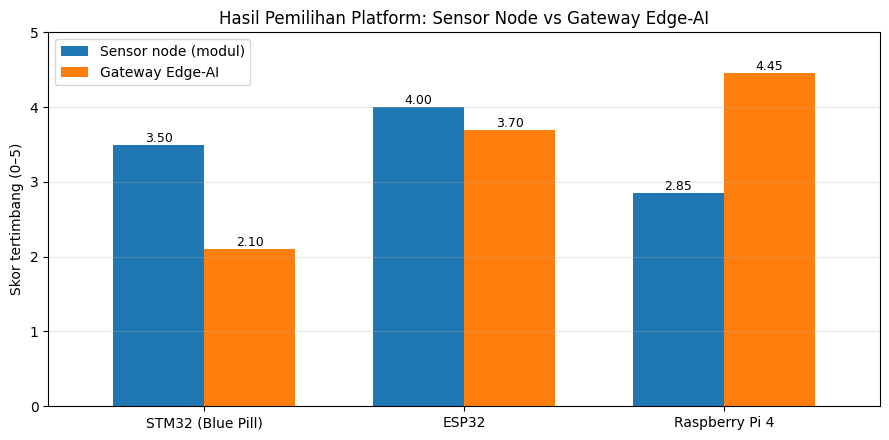

In [3]:
ax = hasil.plot(kind='bar', figsize=(9, 4.5), rot=0, width=0.7)
ax.set_title('Hasil Pemilihan Platform: Sensor Node vs Gateway Edge-AI')
ax.set_ylabel('Skor tertimbang (0–5)')
ax.set_ylim(0, 5)
ax.grid(axis='y', alpha=0.3)
for batang in ax.patches:
    ax.annotate(f'{batang.get_height():.2f}',
                (batang.get_x() + batang.get_width()/2, batang.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

### Analisis soal 1

Pada skenario sensor node, ESP32 unggul karena konsumsi daya dan konektivitasnya lebih cocok untuk pengiriman data sensor. Setelah kasusnya diganti menjadi gateway Edge-AI, rekomendasinya berubah menjadi Raspberry Pi 4. Alasannya, proses pengolahan citra membutuhkan komputasi yang lebih berat dibanding membaca sensor dan mengirim angka. Raspberry Pi 4 memperoleh skor performa serta kemudahan pengembangan lebih tinggi dalam matriks modul.

Menurut saya, perubahan ini masuk akal karena gateway diasumsikan selalu mendapat suplai listrik. Jadi, selisih konsumsi daya tidak sepenting kemampuan menjalankan pemrosesan citra.

---
## 2. Menambahkan ADC 16-bit dan membandingkannya dengan ADC 12-bit

Saya menggunakan sinyal dan tegangan referensi yang sama dengan Hands-On 4: sinyal sinusoidal **0–3,3 V**, frekuensi **2 Hz**, dan 1.000 sampel sepanjang satu detik. Pada kode contoh modul, langkah kuantisasi didefinisikan sebagai `Vref / 2**bit` dan RMSE dipakai untuk mengukur selisih sinyal asli dengan sinyal yang dikuantisasi. Di latihan ini cukup ditambahkan resolusi **16-bit**.

In [4]:
def kuantisasi_adc(sinyal_analog, bit_resolusi, v_ref=3.3):
    level = 2 ** bit_resolusi
    langkah = v_ref / level
    sinyal_terkuantisasi = np.round(sinyal_analog / langkah) * langkah
    return np.clip(sinyal_terkuantisasi, 0, v_ref), langkah

t = np.linspace(0, 1, 1000)
sinyal_asli = 1.65 + 1.65 * np.sin(2 * np.pi * 2 * t)

hasil_adc = []
data_sinyal = {}
for bit in [8, 10, 12, 16]:
    sinyal_adc, langkah = kuantisasi_adc(sinyal_asli, bit)
    rmse = np.sqrt(np.mean((sinyal_asli - sinyal_adc)**2))
    data_sinyal[bit] = sinyal_adc
    hasil_adc.append({'Resolusi (bit)': bit, 'Jumlah level': 2**bit,
                      'Langkah (mV)': langkah*1000, 'RMSE (mV)': rmse*1000})

df_adc = pd.DataFrame(hasil_adc).set_index('Resolusi (bit)')
print(df_adc.round(5).to_string())
print(f"\nLangkah kuantisasi 12-bit / 16-bit = {df_adc.loc[12, 'Langkah (mV)'] / df_adc.loc[16, 'Langkah (mV)']:.0f} kali")
print(f"Penurunan RMSE simulasi = {(1-df_adc.loc[16, 'RMSE (mV)']/df_adc.loc[12, 'RMSE (mV)'])*100:.2f}%")

                Jumlah level  Langkah (mV)  RMSE (mV)
Resolusi (bit)                                       
8                        256       12.8906     3.6666
10                      1024        3.2227     0.9268
12                      4096        0.8057     0.2394
16                     65536        0.0503     0.0145

Langkah kuantisasi 12-bit / 16-bit = 16 kali
Penurunan RMSE simulasi = 93.93%


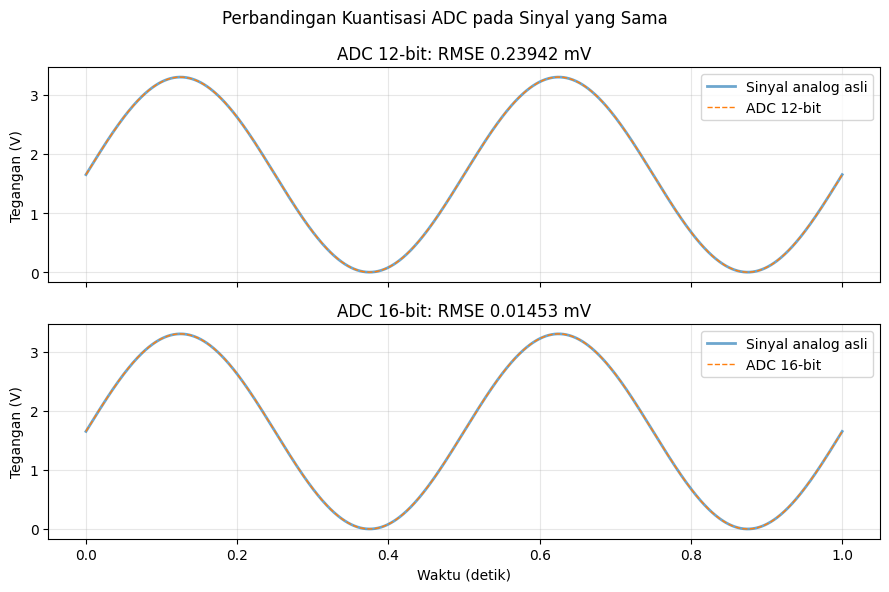

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, bit in zip(axes, [12, 16]):
    ax.plot(t, sinyal_asli, label='Sinyal analog asli', linewidth=2, alpha=0.65)
    ax.plot(t, data_sinyal[bit], '--', label=f'ADC {bit}-bit', linewidth=1)
    ax.set_title(f'ADC {bit}-bit: RMSE {df_adc.loc[bit, "RMSE (mV)"]:.5f} mV')
    ax.set_ylabel('Tegangan (V)')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Waktu (detik)')
plt.suptitle('Perbandingan Kuantisasi ADC pada Sinyal yang Sama')
plt.tight_layout()
plt.show()

### Analisis soal 2

Dari hasil perhitungan, langkah kuantisasi ADC 12-bit sekitar 0,806 mV, sedangkan 16-bit sekitar 0,0504 mV. Jadi, langkah ADC 16-bit 16 kali lebih kecil. RMSE simulasi juga turun, yang berarti hasil digitalnya lebih dekat dengan sinyal analog ideal.

Namun, untuk sensor suhu, saya rasa peningkatannya belum tentu terasa besar. Misalnya sensor analog memiliki sensitivitas 10 mV/°C, satu langkah 12-bit setara sekitar 0,081°C, sedangkan 16-bit sekitar 0,005°C. Ini baru batas resolusi tegangan dalam simulasi, bukan akurasi pengukuran suhu. Kalau sensornya sendiri memiliki galat ±0,5°C atau pembacaannya masih berisik, mengganti ADC menjadi 16-bit tidak langsung membuat hasil suhu 16 kali lebih akurat. Jadi, ADC 16-bit lebih berguna jika sensor, referensi tegangan, dan rangkaiannya memang mendukung ketelitian tambahan tersebut.

---
## 3. Menghitung umur baterai saat interval kirim menjadi 1 menit

Pada Hands-On 6, satu siklus pengukuran berdurasi 300 detik (5 menit) dengan kapasitas baterai 2.000 mAh. Durasi tahap aktif tetap sesuai modul: bangun dan membaca sensor 0,05 detik; koneksi WiFi 2,5 detik; mengirim MQTT 0,3 detik. Yang saya ubah hanya durasi Deep Sleep, supaya total satu siklus menjadi 60 detik. Dengan cara ini perbandingannya adil karena parameter lain tidak ikut diubah.

In [6]:
kapasitas_baterai_mAh = 2000

def estimasi_baterai(interval_detik):
    tahap = [
        {'Tahap': 'Wake-up + Baca Sensor', 'Arus (mA)': 30.0, 'Durasi (s)': 0.05},
        {'Tahap': 'Koneksi WiFi', 'Arus (mA)': 120.0, 'Durasi (s)': 2.5},
        {'Tahap': 'Kirim Data (MQTT)', 'Arus (mA)': 160.0, 'Durasi (s)': 0.3},
    ]
    waktu_aktif = sum(t['Durasi (s)'] for t in tahap)
    if interval_detik <= waktu_aktif:
        raise ValueError('Interval harus lebih panjang daripada seluruh tahap aktif.')
    tahap.append({'Tahap': 'Deep Sleep', 'Arus (mA)': 0.01,
                  'Durasi (s)': interval_detik - waktu_aktif})
    df = pd.DataFrame(tahap)
    df['Muatan (mAs)'] = df['Arus (mA)'] * df['Durasi (s)']
    df['Muatan (mAh)'] = df['Muatan (mAs)'] / 3600
    siklus_harian = 86400 / interval_detik
    konsumsi_harian = df['Muatan (mAh)'].sum() * siklus_harian
    return df, {'Interval (menit)': interval_detik/60,
                'Siklus per hari': siklus_harian,
                'Konsumsi (mAh/hari)': konsumsi_harian,
                'Estimasi umur (hari)': kapasitas_baterai_mAh/konsumsi_harian}

df_5, hasil_5 = estimasi_baterai(300)
df_1, hasil_1 = estimasi_baterai(60)
perbandingan_baterai = pd.DataFrame([hasil_5, hasil_1]).set_index('Interval (menit)')
print('Tahapan kerja saat interval 1 menit:')
print(df_1.round(6).to_string(index=False))
print('\nPerbandingan umur baterai:')
print(perbandingan_baterai.round(2).to_string())
penurunan = (1 - hasil_1['Estimasi umur (hari)']/hasil_5['Estimasi umur (hari)'])*100
print(f'\nPenurunan estimasi umur baterai: {penurunan:.2f}%')

Tahapan kerja saat interval 1 menit:
                Tahap  Arus (mA)  Durasi (s)  Muatan (mAs)  Muatan (mAh)
Wake-up + Baca Sensor    30.0000      0.0500        1.5000        0.0004
         Koneksi WiFi   120.0000      2.5000      300.0000        0.0833
    Kirim Data (MQTT)   160.0000      0.3000       48.0000        0.0133
           Deep Sleep     0.0100     57.1500        0.5715        0.0002

Perbandingan umur baterai:
                  Siklus per hari  Konsumsi (mAh/hari)  Estimasi umur (hari)
Interval (menit)                                                            
5.0000                   288.0000              28.2000               70.9300
1.0000                  1440.0000             140.0300               14.2800

Penurunan estimasi umur baterai: 79.86%


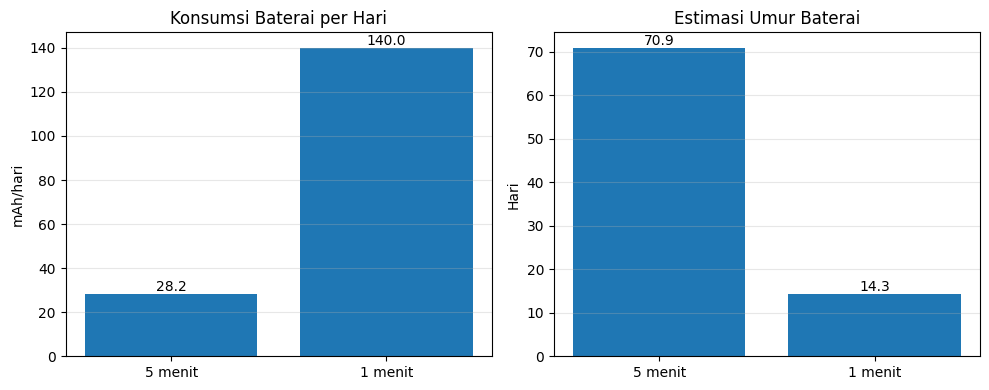

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
intervals = ['5 menit', '1 menit']
axes[0].bar(intervals, [hasil_5['Konsumsi (mAh/hari)'], hasil_1['Konsumsi (mAh/hari)']])
axes[0].set_title('Konsumsi Baterai per Hari')
axes[0].set_ylabel('mAh/hari')
axes[1].bar(intervals, [hasil_5['Estimasi umur (hari)'], hasil_1['Estimasi umur (hari)']])
axes[1].set_title('Estimasi Umur Baterai')
axes[1].set_ylabel('Hari')
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
    for p in ax.patches:
        ax.text(p.get_x() + p.get_width()/2, p.get_height(), f'{p.get_height():.1f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

### Analisis soal 3

Mengubah interval pengiriman dari 5 menit menjadi 1 menit membuat jumlah pengiriman naik dari 288 menjadi 1.440 kali per hari. Keuntungannya, data di dashboard bisa diperbarui lebih sering sehingga perubahan kondisi sensor lebih cepat terlihat. Kekurangannya, modul harus lebih sering menyalakan WiFi dan mengirim MQTT, padahal dua tahap ini memakai arus jauh lebih besar daripada Deep Sleep.

Artinya, responsivitas meningkat tetapi umur baterai berkurang cukup besar. Menurut saya, interval 1 menit cocok untuk kondisi yang perlu dipantau lebih rapat. Kalau parameter sensornya berubah lambat, interval 5 menit lebih hemat. Perhitungan ini masih estimasi ideal sesuai modul: belum memasukkan rugi regulator, penurunan kapasitas baterai, variasi arus nyata, atau koneksi WiFi yang gagal dan harus diulang.

## Kesimpulan

Dari tiga percobaan ini, satu pengaturan hardware tidak otomatis paling bagus untuk semua kebutuhan. Gateway Edge-AI lebih mengutamakan kemampuan komputasi, ADC resolusi tinggi memberi langkah pembacaan lebih kecil tetapi belum tentu memperbaiki akurasi sensor, sedangkan interval kirim yang pendek membuat monitoring lebih responsif dengan biaya energi yang lebih tinggi. Pemilihan akhirnya harus mengikuti kebutuhan perangkat, bukan cuma memilih spesifikasi terbesar.